# 06 | TDX 站點 × 鄉鎮市區

1.	用自己的 TDX 金鑰取得資料，而且金鑰不出現在程式碼、輸出與筆記中。
2.	分辨 set_crs 與 to_crs，能用座標的數值範圍判斷 CRS。
3.	用空間連接（sjoin）把站點對應到鄉鎮市區，並檢查連接結果。
4.	選一種標準化方式畫面量圖，並說明它講了什麼故事。

## 0. 路徑與中文字型

沿用 `00_Colab環境設定範本.ipynb` 的兩個儲存格。本週多了三個路徑：鄉鎮市區界、老師的備援快照，以及你自己從 TDX 抓下來的資料。

In [148]:
import sys
import urllib.request
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib import font_manager

"""路徑設定"""
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/115-1_GISprog")

    """安裝相關套件"""
    %pip install -q mapclassify
else:
    # 備援：本機執行時，notebook 位於 115-1_GISprog/notebooks/，上一層就是專案資料夾
    PROJECT_DIR = Path.cwd().parent

"""字型設定"""
FONT_DIR = PROJECT_DIR / "fonts"
FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FONT_PATH = FONT_DIR / "TaipeiSansTCBeta-Regular.ttf"

if not FONT_PATH.exists():
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(FONT_URL, FONT_PATH)

font_manager.fontManager.addfont(str(FONT_PATH))     # 告訴 Matplotlib：「這個字型檔可以使用」
plt.rcParams["font.family"] = "Taipei Sans TC Beta"  # 指定之後畫圖預設使用這個中文字型
plt.rcParams["axes.unicode_minus"] = False           # 避免負號 − 顯示異常
print("已設定中文字型：", FONT_PATH.name)

已設定中文字型： TaipeiSansTCBeta-Regular.ttf


## 1. 選縣市、準備資料
* 選一個縣市。 TDX 自行車站點 API 接受以下 15 個縣市（老師 2026-10-12 實測）：
    | 代碼 | 縣市 | 代碼 | 縣市 | 代碼 | 縣市
    |:---:|:---:|:---:|:---:|:---:|:---:|
    | Taipei | 臺北市 | Kaohsiung | 高雄市 | YunlinCounty | 雲林縣
    | NewTaipei | 新北市 | Hsinchu | 新竹市 | ChiayiCounty | 嘉義縣
    | Taoyuan | 桃園市 | HsinchuCounty | 新竹縣 | Chiayi | 嘉義市
    | Taichung | 臺中市 | MiaoliCounty | 苗栗縣 | PingtungCounty | 屏東縣
    | Tainan | 臺南市 | ChanghuaCounty | 彰化縣 | TaitungCounty | 臺東縣
    * 彰化縣是課堂範例，請選其他縣市。
    * 新竹市只有 3 區、嘉義市只有 2 區，面量圖看不出差異，不建議選。
    * 雲林縣與彰化縣一樣是 Moovo，不是 YouBike，欄位也比較少。
* 確認雲端硬碟或是本機的 `115-1_GISprog/data/raw/` 已有課堂的 Taiwan_boundaries 資料夾。
* 在 `notebooks/` 建立 `06_tdx_town.ipynb`。可以請 agent 參考課堂的 `06_GeoPandas與TDX.ipynb` 撰寫，但每一步的結果都要自己檢查。


In [149]:
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"


TOWN_SHP = RAW_DIR / "Taiwan_boundaries" / "Town" / "Taiwan_town.shp"  # 鄉鎮市區界
BACKUP_DIR = RAW_DIR / "tdx_station_20261012"                          # 老師 10/12 抓的備援快照
TDX_DIR = RAW_DIR / "tdx"                                              # 你自己從 TDX 抓的資料

for p in [TOWN_SHP, BACKUP_DIR]:
    if not p.exists():
        raise FileNotFoundError(f"找不到 {p}，請依課前準備上傳 W6_課堂資料")

print("Taiwan_boundaries 資料夾讀取成功")
print("執行環境：", "Google Colab" if IN_COLAB else "本機")  

CITY = "Taichung" 
CITY_DICT = {
                "Taipei": "臺北市", "NewTaipei": "新北市", "Taoyuan": "桃園市", "Taichung": "臺中市", "Tainan": "臺南市",
                "Kaohsiung": "高雄市", "Hsinchu": "新竹市", "HsinchuCounty": "新竹縣", "MiaoliCounty": "苗栗縣", "ChanghuaCounty": "彰化縣",
                "YunlinCounty": "雲林縣", "ChiayiCounty": "嘉義縣", "Chiayi": "嘉義市", "PingtungCounty": "屏東縣", "TaitungCounty": "臺東縣"
            }     

if CITY_DICT.get(CITY) == None:
    raise ValueError("CITY 的值錯誤，請確認選擇的程式代號是否輸入正確")
else:
    print("所選縣市：" + str(CITY_DICT.get(CITY)))

Taiwan_boundaries 資料夾讀取成功
執行環境： 本機
所選縣市：臺中市


## 2. 用自己的金鑰取得站點資料
* 若使用 Colab ，在其左側 🔑（Secrets）新增 `TDX_CLIENT_ID`、`TDX_CLIENT_SECRET`，打開「Notebook access」。
* 若使用本機環境，新增一個`.env`環境變數檔案，格式如下所示，並確認`.gitgnore`內容有`.env`，以避免環境津要被 git 追蹤進而導致外洩
    ```
    TDX_CLIENT_ID = Your TDX_CLIENT_ID
    TDX_CLIENT_SECRET = Your TDX_CLIENT_SECRET
    ```
* 用課堂的 get_token()、get_json()（含 token 快取）取得整個縣市的站點資料：/v2/Bike/Station/City/{你的縣市代碼}。
* 把回傳的 JSON 存到 data/raw/tdx/，檔案已存在就讀檔，不再呼叫 API。
* 轉成 GeoDataFrame（crs="EPSG:4326"）。


In [150]:
import os
import json
import time
import requests
import pandas as pd
import geopandas as gpd

from datetime import datetime
from zoneinfo import ZoneInfo
from dotenv import load_dotenv


"""讀取環境變數"""
if IN_COLAB:
    from google.colab import userdata
    for k in ["TDX_CLIENT_ID", "TDX_CLIENT_SECRET"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception as e:  # 沒設定密鑰，或沒打開 Notebook access
            print(f"讀不到 {k}：{type(e).__name__}")

    HAS_KEY = all(os.environ.get(k) for k in ["TDX_CLIENT_ID", "TDX_CLIENT_SECRET"])

else:
    HAS_KEY = load_dotenv()

print("TDX 金鑰已載入" if HAS_KEY else "沒有 TDX 金鑰，Part C 將改讀老師的備援快照")


AUTH_URL = "https://tdx.transportdata.tw/auth/realms/TDXConnect/protocol/openid-connect/token"
API_BASE = "https://tdx.transportdata.tw/api/basic"

_token = {"value": None, "expires": 0}
call_record = []   # 本次執行的紀錄：api（呼叫 API）、token（換 token）、cache（讀快照，沒連 TDX）
CALL_LOG = TDX_DIR / "call_log.csv"   # 真的連到 TDX 的呼叫會累計寫入，重開 kernel 也不會歸零


"""記一筆紀錄；真的連到 TDX 的（api、token）另外附加到 call_log.csv"""
def log_call(kind, path, status=None):
    rec = {"time": datetime.now(ZoneInfo("Asia/Taipei")).strftime("%Y-%m-%d %H:%M:%S"),
           "type": kind, "path": path, "status": status}
    call_record.append(rec)
    if kind != "cache":
        TDX_DIR.mkdir(parents=True, exist_ok=True)
        pd.DataFrame([rec]).to_csv(CALL_LOG, mode="a", header=not CALL_LOG.exists(),
                                   index=False, encoding="utf-8-sig")


"""回傳 access token；還沒過期就沿用（token 快取）。"""
def get_token():
    if _token["value"] and time.time() < _token["expires"] - 60:
        return _token["value"]
    r = requests.post(AUTH_URL, data={
        "grant_type": "client_credentials",
        "client_id": os.environ["TDX_CLIENT_ID"],
        "client_secret": os.environ["TDX_CLIENT_SECRET"],
    }, timeout=30)
    log_call("token", "/auth/token", r.status_code)
    r.raise_for_status()
    data = r.json()
    _token["value"] = data["access_token"]
    _token["expires"] = time.time() + data["expires_in"]
    return _token["value"]


"""呼叫 TDX 基礎服務，回傳解析後的 JSON。"""
def get_json(path, params=None):
    headers = {"authorization": f"Bearer {get_token()}", "Accept-Encoding": "gzip"}
    r = requests.get(API_BASE + path, headers=headers,
                     params={"$format": "JSON", **(params or {})}, timeout=30)
    log_call("api", path, r.status_code)
    r.raise_for_status()
    return r.json()

"""取得縣市站點快照"""
TODAY = datetime.now(ZoneInfo("Asia/Taipei")).strftime("%Y%m%d")
SNAP = TDX_DIR / f"station_{CITY}_{TODAY}.json"

if SNAP.exists():
    print("讀取今天已存的快照：", SNAP.name)
    data = json.loads(SNAP.read_text(encoding="utf-8"))
    log_call("cache", str(SNAP.name))
elif HAS_KEY:
    data = get_json(f"/v2/Bike/Station/City/{CITY}")
    TDX_DIR.mkdir(parents=True, exist_ok=True)
    SNAP.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    print("已從 TDX 取得並存檔：", SNAP.name)
else:
    SNAP = BACKUP_DIR / f"station_{CITY}.json"
    print("改讀老師的備援快照：", SNAP.name)
    data = json.loads(SNAP.read_text(encoding="utf-8"))
    log_call("cache", str(SNAP.name))

print("站點數：", len(data))

"""轉成 4326"""
station = pd.json_normalize(data)
station = gpd.GeoDataFrame(pd.json_normalize(data),
    geometry=gpd.points_from_xy(station["StationPosition.PositionLon"], station["StationPosition.PositionLat"]),
    crs="EPSG:4326",
)
print(station.crs)

TDX 金鑰已載入
讀取今天已存的快照： station_Taichung_20261028.json
站點數： 1842
EPSG:4326


## 3. 空間連接與計數
* 讀取 `Taiwan_boundaries/Town/Taiwan_town.shp`，印出兩個圖層的 CRS 與 total_bounds，統一 CRS 後再做 `sjoin`。
* 連接後檢查三件事，並把檢查的程式與結果留在 notebook 裡：
    * 連接前後的筆數是否相同？
    * 有沒有沒配對到鄉鎮的站點？
    * 有沒有不在你選的縣市的站點？有的話，決定要不要算進去，並在決策表說明。
* 計算每個鄉鎮市區的站點數。沒有站點的鄉鎮也要列出來，記為 0。
* 驗證：各鄉鎮站點數的加總，等於你決定納入的站點總數。


In [ ]:
"""印出兩個圖層的 CRS 與 total_bounds"""
print("站點：", station.crs, station.total_bounds)

town = gpd.read_file(TOWN_SHP)
print("鄉鎮區界：", town.crs, town.total_bounds)

"""sjoin"""
station_3826 = station.to_crs(town.crs)     # 統一 CRS
connect = gpd.sjoin(
    station_3826,
    town[["TOWNCODE", "COUNTYNAME", "TOWNNAME", "geometry"]],
    how="left",
    predicate="within",
)

print("站點數：", len(station_3826), "→ 連接後：", len(connect))
print("沒有配對到鄉鎮的站點：", connect["TOWNNAME"].isna().sum())

"""檢查：不在所選縣市的站點（含沒配對到鄉鎮的 NaN）"""
outside = connect[connect["COUNTYNAME"] != CITY_DICT.get(CITY)]
print("不在", CITY_DICT.get(CITY), "的站點：", len(outside))

"""只納入所選縣市內的站點"""
included = connect[connect["COUNTYNAME"] == CITY_DICT.get(CITY)]
print("納入：", len(included), "／排除：", len(connect) - len(included))

"""計算每個鄉鎮市區的站點數（用 TOWNCODE，避免不同縣市同名的區被合併）"""
township = included.groupby(["TOWNCODE", "TOWNNAME"]).size().sort_values(ascending=False)
print("有站點的鄉鎮：", len(township))
print(str(CITY_DICT.get(CITY)) + "的鄉鎮市：", (town["COUNTYNAME"] == CITY_DICT.get(CITY)).sum())

outside[["StationName.Zh_tw", "COUNTYNAME", "TOWNNAME",
         "StationPosition.PositionLon", "StationPosition.PositionLat"]]

站點： EPSG:4326 [120.498432  24.023001 121.00537   24.43013 ]
鄉鎮區界： EPSG:3826 [ 147522.21879192 2422004.77310209  361519.68133834 2836375.81627143]
站點數： 1842 → 連接後： 1842
沒有配對到鄉鎮的站點： 0
不在 臺中市 的站點： 0
納入： 1842 ／排除： 0
有站點的鄉鎮： 29
臺中市的鄉鎮市： 29


,StationName.Zh_tw,COUNTYNAME,TOWNNAME,StationPosition.PositionLon,StationPosition.PositionLat


In [152]:
township

TOWNCODE  TOWNNAME
66000060  西屯區         220
66000080  北屯區         208
66000070  南屯區         128
66000030  南區           95
66000090  豐原區          89
66000120  清水區          88
66000040  西區           84
66000020  東區           82
66000050  北區           79
66000280  大里區          79
66000230  烏日區          76
66000270  太平區          74
66000130  沙鹿區          63
66000140  梧棲區          61
66000110  大甲區          60
66000170  潭子區          50
66000240  大肚區          47
66000260  霧峰區          42
66000250  龍井區          37
66000150  后里區          33
66000180  大雅區          30
66000160  神岡區          29
66000210  外埔區          27
66000220  大安區          20
66000100  東勢區          17
66000010  中區           11
66000190  新社區           8
66000200  石岡區           3
66000290  和平區           2
dtype: int64

## 4. 標準化與地圖
* 選一種標準化方式：每平方公里站點數或每萬人站點數。
    * 面積要在 EPSG:3826 下計算。
    * `Taiwan_town.shp` 的 `CENSUS` 欄位沒有說明年份（課堂檢查約為 2019 年前後的戶籍人口）。用它計算時，要在決策表說明；也可以改用內政部戶政司的最新資料。
* 畫面量圖：中文標題、圖例；把站點疊上去。
* 用 `explore()` 疊在底圖上目視檢查：挑 2–3 個站點，確認它們真的在連接到的鄉鎮裡。
* 輸出 GPKG 到` data/processed/`，至少包含鄉鎮圖層（含站點數與標準化結果）。不要存成 Shapefile：中文欄名會被截斷。


In [153]:
"""沒站點鄉鎮補 0"""
location = town[town["COUNTYNAME"] == CITY_DICT.get(CITY)].copy()
location["站點數"] = location["TOWNCODE"].map(included["TOWNCODE"].value_counts()).fillna(0).astype(int)

print("站點數加總：", location["站點數"].sum(), "（應該等於納入的站點數", len(included), "）")
assert location["站點數"].sum() == len(included)
location.loc[location["站點數"] == 0, ["TOWNNAME", "站點數"]]


站點數加總： 1842 （應該等於納入的站點數 1842 ）


,TOWNNAME,站點數


In [154]:
"""每平方公里站點數"""
location["面積_km2"] = location.area / 1e6
location["每平方公里站點數"] = location["站點數"] / location["面積_km2"]

location[["TOWNNAME", "站點數", "面積_km2", "每平方公里站點數"]].sort_values("每平方公里站點數", ascending=False).head(8).round(2)

,TOWNNAME,站點數,面積_km2,每平方公里站點數
214,西區,84,6.35,13.23
212,東區,82,6.69,12.26
213,南區,95,7.82,12.15
211,中區,11,0.93,11.86
215,北區,79,7.58,10.42
216,西屯區,220,39.94,5.51
12,南屯區,128,30.45,4.20
217,北屯區,208,61.54,3.38


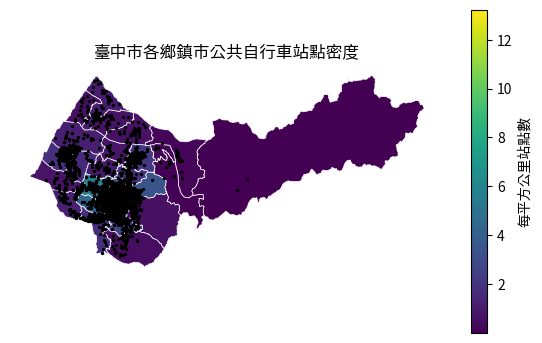

In [155]:
"""面量圖"""
fig, ax = plt.subplots(figsize=(7, 7))
location.plot(column="每平方公里站點數", cmap="viridis", legend=True, ax=ax,
          edgecolor="white", linewidth=0.5,
          legend_kwds={"label": "每平方公里站點數", "shrink": 0.6})
included.plot(ax=ax, color="black", markersize=2)
ax.set_title(str(CITY_DICT.get(CITY)) + "各鄉鎮市公共自行車站點密度")
ax.set_axis_off()
plt.show()

"""explore"""
# 臺灣通用電子地圖（內政部國土測繪中心 WMTS）；注意網址是 {z}/{y}/{x}
map_web = "https://wmts.nlsc.gov.tw/wmts/EMAP/default/GoogleMapsCompatible/{z}/{y}/{x}"
map_from = "臺灣通用電子地圖 © 內政部國土測繪中心"

m = location.explore(
    column="每平方公里站點數", cmap="viridis",
    tooltip=["TOWNNAME", "站點數", "每平方公里站點數"],
    style_kwds={"fillOpacity": 0.5},
    tiles=map_web, attr=map_from)

included.explore(m=m, color="red", marker_kwds={"radius": 3}, tooltip=["StationName.Zh_tw", "StationUID", "TOWNNAME"])

In [156]:
"""存檔"""
import pyogrio

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FILNAME = "w6_" + str(CITY) + "_station.gpkg"
GPKG = PROCESSED_DIR / FILNAME

location.to_file(GPKG, layer="town_density", driver="GPKG")
included.drop(columns="index_right").to_file(GPKG, layer="stations", driver="GPKG")

print("儲存於", GPKG)
print(pyogrio.list_layers(GPKG))
read = gpd.read_file(GPKG, layer="town_density")
print(read.crs, len(read), read.columns.tolist()[-3:])

儲存於 c:\作業資料夾\112-1~115-1 程式設計相關課程\課堂習題或回家作業\python\python\GIS_Programming\data\processed\w6_Taichung_station.gpkg
[['town_density' 'Polygon']
 ['stations' 'Point']]
EPSG:3826 29 ['面積_km2', '每平方公里站點數', 'geometry']


## 6. API 呼叫紀錄

In [ ]:
"""本次執行"""
rec = pd.DataFrame(call_record, columns=["time", "type", "path", "status"])
n = rec["type"].value_counts()
print("本次執行：呼叫 API", n.get("api", 0), "次、換 token", n.get("token", 0), "次、讀快照", n.get("cache", 0), "次")

"""歷史：掃描 data/raw/tdx/ 的快照檔，每個檔 = 一次成功的 API 呼叫（檔名格式 station_{縣市}_{YYYYMMDD}.json）"""
snap = pd.DataFrame(
    [{"date": f.stem.split("_")[-1], "city": f.stem.split("_")[1], "file": f.name}
     for f in TDX_DIR.glob("station_*_*.json")],
    columns=["date", "city", "file"],
)
snap["date"] = pd.to_datetime(snap["date"], format="%Y%m%d").dt.strftime("%Y-%m-%d")
summary = snap.groupby("date").agg(快照檔推算=("file", "size"), 縣市=("city", ", ".join))

"""累計：call_log.csv（加入紀錄功能之後才有）"""
if CALL_LOG.exists():
    log = pd.read_csv(CALL_LOG, encoding="utf-8-sig")
    log["date"] = log["time"].str[:10]
    counts = log.pivot_table(index="date", columns="type", values="path", aggfunc="count", fill_value=0)
    summary = summary.join(counts.rename(columns={"api": "call_log_api", "token": "call_log_token"}), how="outer")
else:
    print("尚無 call_log.csv（還沒真的連過 TDX），下表只有快照檔推算")

print("每日 API 呼叫次數（請和 TDX 會員中心的使用統計比對；會員中心通常隔天才更新）")
display(summary.fillna(0))


本次執行：呼叫 API 0 次、換 token 0 次、讀快照 1 次
尚無 call_log.csv（還沒真的連過 TDX），下表只有快照檔推算
每日 API 呼叫次數（請和 TDX 會員中心的使用統計比對；會員中心通常隔天才更新）


,快照檔推算,縣市
date,,
2026-10-22,1,Taichung
2026-10-28,3,"ChanghuaCounty, PingtungCounty, Taichung"
